# Coupon Acceptance Prediction

## Business problem
An in-vehicle recommender can show a driver a coupon for a nearby place (coffee house, bar, take-away, restaurant). Coupons that get rejected waste marketing budget and annoy users. If we can predict **who will accept which coupon, in which situation**, we can send fewer, better-targeted offers.

## Goal
Predict whether a driver will accept a coupon (`Y = 1`) from three groups of information: the **driving situation**, the **coupon**, and the **person**. Then identify which factors drive acceptance.

## Data
UCI *In-Vehicle Coupon Recommendation* dataset: about 12,600 responses from a **survey of hypothetical driving scenarios** (collected on Amazon Mechanical Turk). Each row is one person's answer to one scenario. This is stated intent, not observed purchase behaviour.

## Approach
1. Data quality audit and cleaning
2. Exploratory analysis (EDA) with an insight written under every chart
3. Baseline model (logistic regression), then Random Forest and XGBoost
4. Evaluation with ROC-AUC (primary), F1, precision, recall and 5-fold cross-validation
5. Explainability (feature importance and SHAP) and business recommendations

## Success metric
**ROC-AUC** is the primary metric because it does not depend on a threshold. **F1** is secondary because wasted coupons (false positives) and missed acceptances (false negatives) both cost money.

## 1. Setup and data loading
Importing the libraries and loading the CSV. All file paths are relative to the repo folder, so the notebook must be opened from the repo root.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

df = pd.read_csv("data/in-vehicle-coupon-recommendation.csv")
print("Rows, columns:", df.shape)

Rows, columns: (12684, 26)


In [2]:
df.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null  str  
 16  CoffeeHouse    

**First look:** the data has 12,684 rows and 26 columns. Most columns are categorical text (for example `coupon`, `passanger`, `weather`), and only a few are numeric. The target is `Y`.

The column names fall into four groups:
- **Driving situation:** `destination`, `passanger`, `weather`, `temperature`, `time`, `direction_same`, `direction_opp`, `toCoupon_GEQ15min`, `toCoupon_GEQ25min`
- **Coupon:** `coupon`, `expiration`
- **Person:** `gender`, `age`, `maritalStatus`, `has_children`, `education`, `occupation`, `income`
- **Habits:** `Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50` (how often the person normally visits each type of place)

Note: `passanger` is spelled this way in the original dataset, so I keep the original name.

## 2. Data quality audit
Before any modelling I check the class balance, missing values and duplicates. Every decision made here is documented right below the check.

Y
Accepted    56.8
Rejected    43.2
Name: proportion, dtype: float64


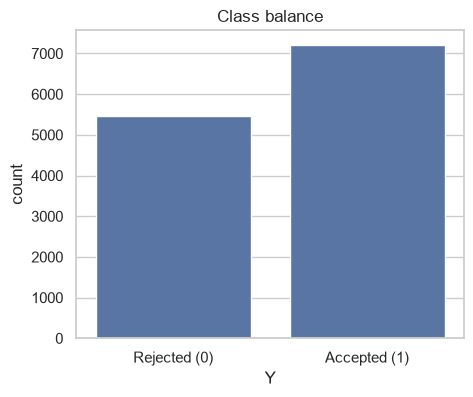

In [4]:
balance = df["Y"].value_counts(normalize=True).rename({0: "Rejected", 1: "Accepted"})
print((balance * 100).round(1))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Y", color="#4c72b0")
plt.xticks([0, 1], ["Rejected (0)", "Accepted (1)"])
plt.title("Class balance")
plt.show()

**Insight:** 57% of coupons were accepted and 43% were rejected. The target is only mildly imbalanced, so a model that always predicts "accepted" would already score about 57% accuracy. Accuracy alone is therefore a weak metric here, and I will track **ROC-AUC and F1** as well and use **stratified** splits so train and test keep the same ratio.

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values per column:")
print(missing)
print("\nPercent missing:")
print((missing / len(df) * 100).round(2))
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
car                     12576
CoffeeHouse               217
Restaurant20To50          189
CarryAway                 151
RestaurantLessThan20      130
Bar                       107
dtype: int64

Percent missing:
car                     99.15
CoffeeHouse              1.71
Restaurant20To50         1.49
CarryAway                1.19
RestaurantLessThan20     1.02
Bar                      0.84
dtype: float64

Duplicate rows: 74


**Findings:**
- `car` is missing in about 99% of rows, so it carries almost no usable information.
- Five visit-frequency columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`) each have only about less than 2% missing values.
- There are 74 duplicate rows.

In [6]:
rows_before = len(df)

# 1) 'car' is almost entirely empty, so imputing it would only add noise
df = df.drop(columns=["car"], errors="ignore")

# 2) Remove exact duplicate rows
df = df.drop_duplicates()

# 3) Fill the few missing habit values with the most common value
freq_cols = ["Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]
for col in freq_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 4) Drop columns that have the same value in every row (zero information)
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns dropped:", constant_cols)
df = df.drop(columns=constant_cols)

print("Duplicate rows removed:", rows_before - len(df))
print("Missing values left:", df.isnull().sum().sum())
print("Final shape:", df.shape)

Constant columns dropped: ['toCoupon_GEQ5min']
Duplicate rows removed: 74
Missing values left: 0
Final shape: (12610, 24)


### Cleaning decisions and why
| Decision | Reason |
|---|---|
| Dropped `car` | More than 99% missing, imputing it would add noise |
| Removed duplicate rows | Duplicates can appear in both train and test and inflate the score |
| Filled habit columns with the mode | Only a small share of rows was affected, so the impact on the distribution is minimal |
| Dropped constant columns (`toCoupon_GEQ5min`) | Same value in every row, so a model cannot learn anything from it |

After cleaning, the dataset has 12,610 rows and no missing values.

## 3. Exploratory data analysis
The helper function below prints the acceptance rate and the number of rows (`n`) for each category, and draws a bar chart. The **red dashed line** is the overall acceptance rate, so any bar above it is a segment that accepts more than average. I always check `n` before trusting a gap, because small groups give unstable rates.

In [7]:
def acceptance_plot(col, order=None, rotate=0, figsize=(8, 4.5)):
    """Print the acceptance rate table and draw a bar chart for one column."""
    table = (
        df.groupby(col)["Y"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "acceptance_rate", "count": "n"})
    )
    if order is not None:
        order = [o for o in order if o in table.index]
        table = table.loc[order]
    else:
        table = table.sort_values("acceptance_rate", ascending=False)

    shown = table.copy()
    shown["acceptance_rate"] = (shown["acceptance_rate"] * 100).round(1)
    print(shown)

    overall = df["Y"].mean()
    plt.figure(figsize=figsize)
    sns.barplot(x=list(table.index.astype(str)), y=table["acceptance_rate"].values, color="#4c72b0")
    plt.axhline(overall, color="red", linestyle="--", label=f"Overall rate ({overall:.0%})")
    plt.ylabel("Acceptance rate")
    plt.xlabel(col)
    plt.xticks(rotation=rotate, ha="right" if rotate else "center")
    plt.ylim(0, 1)
    plt.title(f"Coupon acceptance rate by {col}")
    plt.legend()
    plt.show()

### 3.1 Coupon type
The coupon type is the most direct lever a marketer controls, so I start here.

                       acceptance_rate     n
coupon                                      
Carry out & Take away             73.4  2344
Restaurant(<20)                   70.8  2779
Coffee House                      49.9  3989
Restaurant(20-50)                 44.2  1488
Bar                               41.0  2010


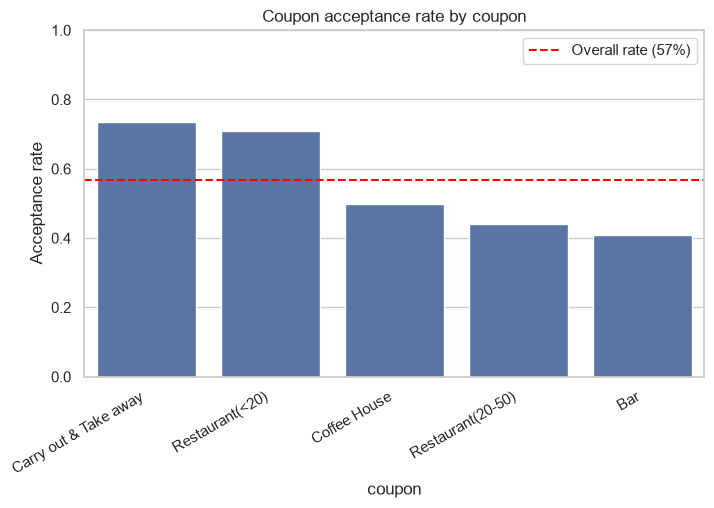

In [8]:
acceptance_plot("coupon", rotate=30)

**Insight:** Acceptance is highest for Carry out & Take away (73.4%) and lowest for Bar (41%), a gap of 32.4 percentage points. The overall rate is 57%.

**So what:** Coupon type is likely to be one of the strongest predictors. Offers for Carry Out & Take Away, Retaurant(<20) perform above average, while Coffee House, Restaurant(20-50) and Bar offers need better targeting (right person, right moment) to be worth sending.

### 3.2 Who is in the car

           acceptance_rate     n
passanger                       
Friend(s)             67.3  3292
Partner               59.4  1069
Alone                 52.4  7248
Kid(s)                50.4  1001


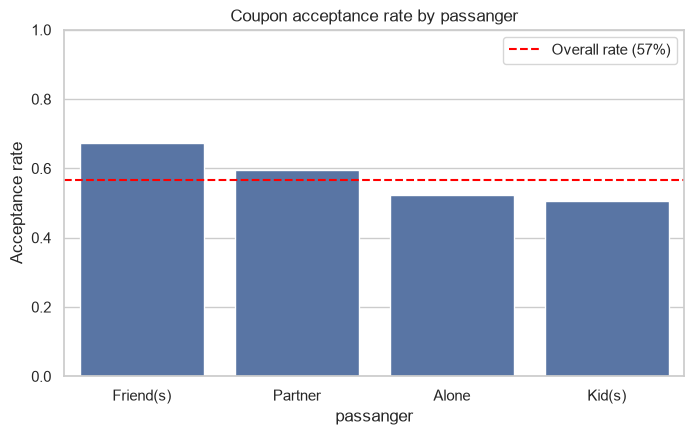

In [9]:
acceptance_plot("passanger")

**Insight:** Drivers travelling with Friends accept 67.3% of coupons, versus 50.4% when travelling with Kids. Check the `n` column: the "Kid(s)" group is 1001 rows, so interpret it carefully.

**So what:** The in-car context changes behaviour. A model should capture the *interaction* between passenger and coupon type (see the heatmap in section 3.7).

### 3.3 Time of day and destination

      acceptance_rate     n
time                       
7AM              49.9  3114
10AM             60.8  2271
2PM              66.2  2006
6PM              58.4  3220
10PM             50.8  1999


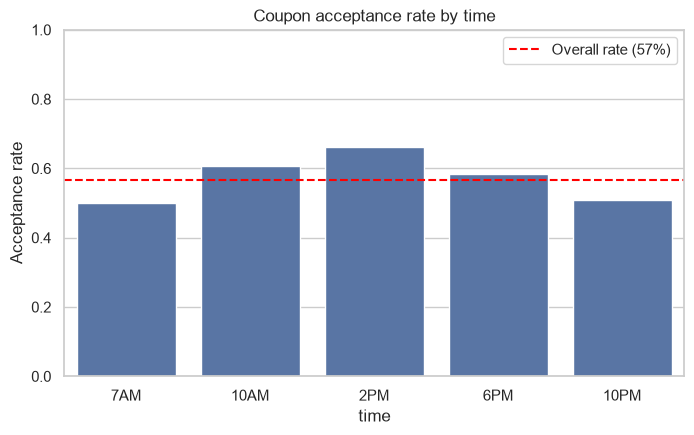

                 acceptance_rate     n
destination                           
No Urgent Place             63.3  6266
Home                        50.6  3230
Work                        49.9  3114


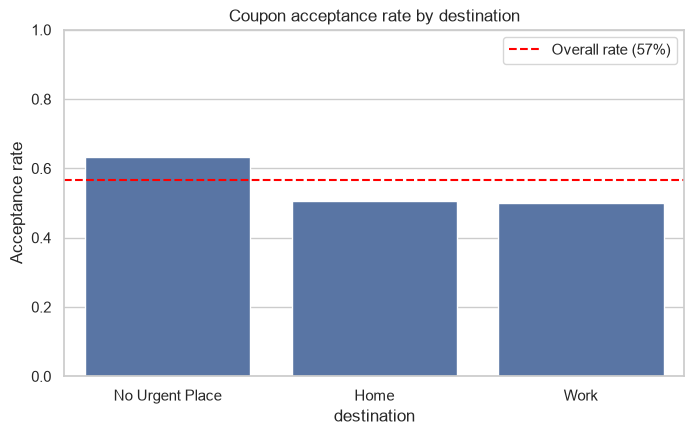

In [10]:
acceptance_plot("time", order=["7AM", "10AM", "2PM", "6PM", "10PM"])
acceptance_plot("destination")

**Insight:** Acceptance peaks at **2PM** (66%) and is lowest at  **7AM** (50%). By destination, drivers going **No Urgent Place** accept 63% versus 50% for **Work**.

**So what:** Timing matters. Coupons are more welcome when the driver is at No Urgent Place, and less welcome when they are heading on Work (It means "No Urgent Place" suggests more flexibility than "Work").

### 3.4 Weather, temperature and offer expiry

         acceptance_rate      n
weather                        
Sunny               59.3  10011
Snowy               47.2   1397
Rainy               46.3   1202


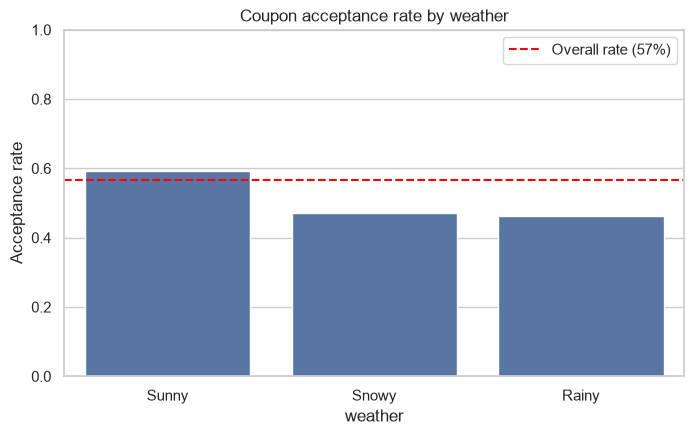

             acceptance_rate     n
temperature                       
80                      59.9  6475
55                      53.7  3830
30                      53.1  2305


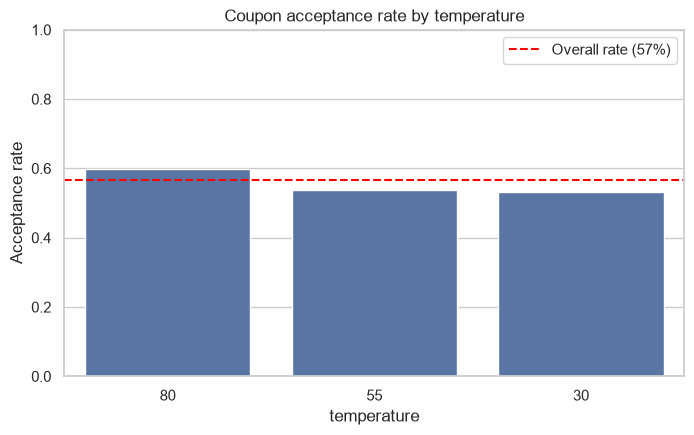

            acceptance_rate     n
expiration                       
1d                     62.4  7031
2h                     49.6  5579


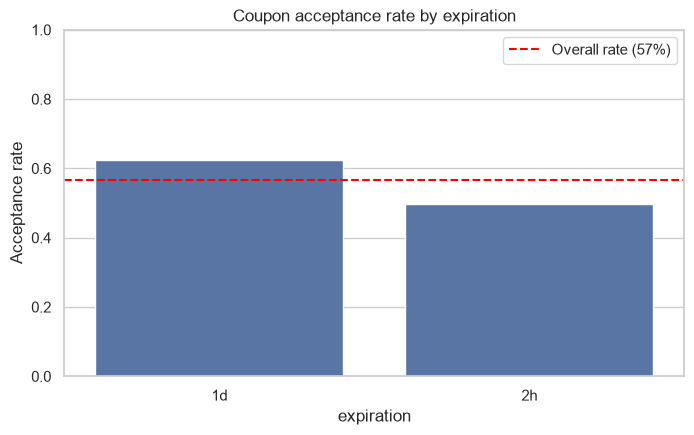

In [11]:
acceptance_plot("weather")
acceptance_plot("temperature")
acceptance_plot("expiration")

**Insight:** **Sunny** weather and a temperature of **80** degrees show the highest acceptance (60%). Coupons valid for **1d** are accepted **62%** 13 points more often than those valid for **2h**.

**So what:** Weather and temperature are partly proxies for drinks and food preferences (for example, warm weather may favour cold drinks and ice cream style offers). The expiry time is a controllable factor: a **1d** expiry looks better than **2h**.

### 3.5 Who the person is ??

         acceptance_rate     n
age                           
below21             63.2   544
21                  59.8  2642
26                  59.5  2548
31                  54.6  2019
36                  53.5  1317
41                  57.2  1089
46                  57.3   670
50plus              50.7  1781


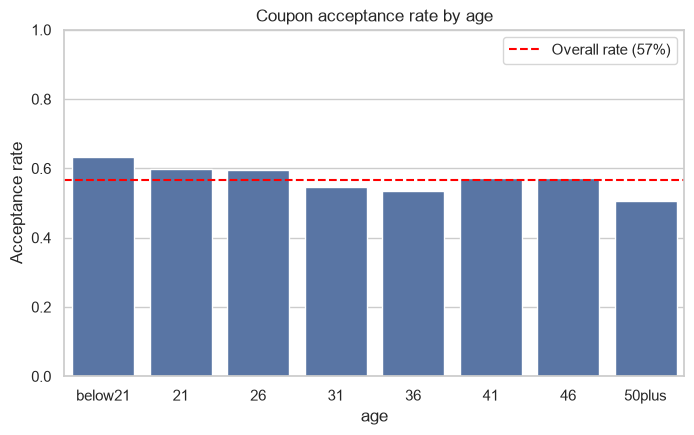

                  acceptance_rate     n
income                                 
Less than $12500             59.2  1034
$12500 - $24999              57.4  1825
$25000 - $37499              59.3  2006
$37500 - $49999              56.3  1795
$50000 - $62499              59.5  1655
$62500 - $74999              52.6   843
$75000 - $87499              48.4   856
$87500 - $99999              52.9   879
$100000 or More              57.8  1717


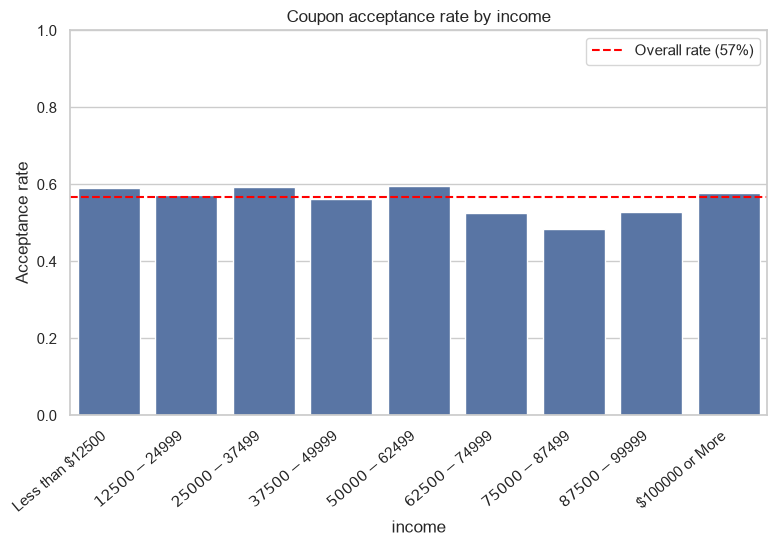

        acceptance_rate     n
gender                       
Male               59.0  6141
Female             54.6  6469


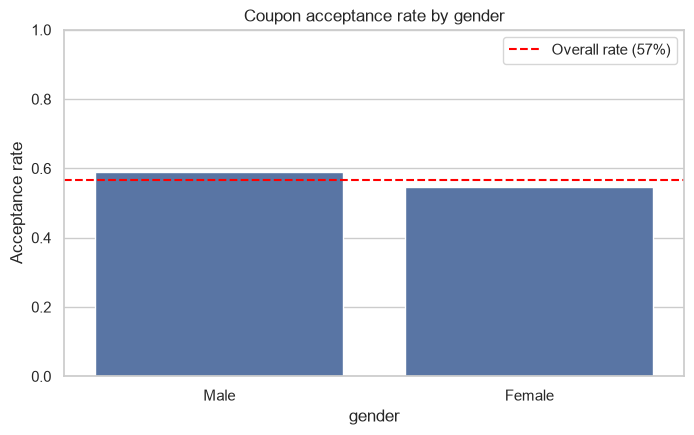

                   acceptance_rate     n
maritalStatus                           
Single                        60.5  4716
Unmarried partner             56.1  2185
Married partner               54.2  5068
Divorced                      52.6   511
Widowed                       47.7   130


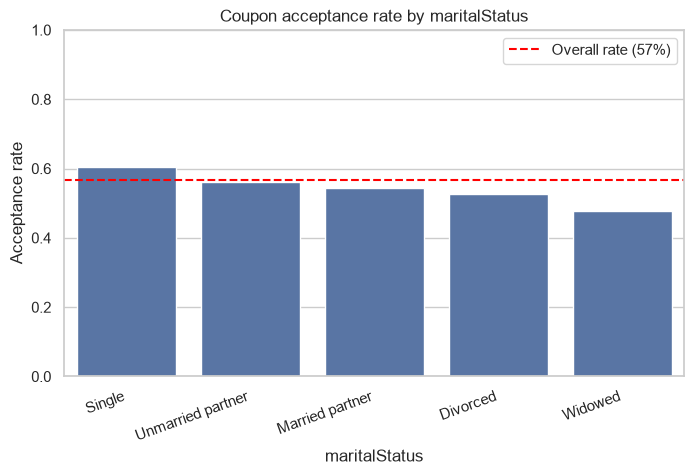

              acceptance_rate     n
has_children                       
0                        58.6  7383
1                        54.1  5227


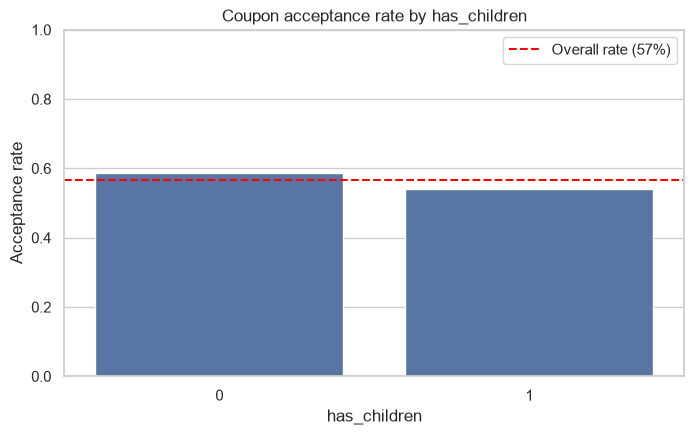

In [12]:
age_order = ["below21", "21", "26", "31", "36", "41", "46", "50plus"]
income_order = [
    "Less than $12500",
    "$12500 - $24999",
    "$25000 - $37499",
    "$37500 - $49999",
    "$50000 - $62499",
    "$62500 - $74999",
    "$75000 - $87499",
    "$87500 - $99999",
    "$100000 or More",
]

acceptance_plot("age", order=age_order)
acceptance_plot("income", order=income_order, rotate=40, figsize=(9, 5))
acceptance_plot("gender")
acceptance_plot("maritalStatus", rotate=20)
acceptance_plot("has_children")

**Insight:** Younger drivers (below 21) accept more often (63%) than older drivers (51%). Income shows a **no clear trend** pattern. Gender and children make a difference of only **4.5%** percentage points.

**So what:** Demographics have a less effect compared with the coupon and the situation. This is common, because who a person is changes slowly, while the situation changes with every trip. I expect demographic features to rank lower in the final model.

### 3.6 Does past behaviour match the coupon?
For each coupon type I look at how often the person *normally* visits that kind of place. For example, for Coffee House coupons I use the `CoffeeHouse` habit column. This tests whether existing habits predict acceptance.

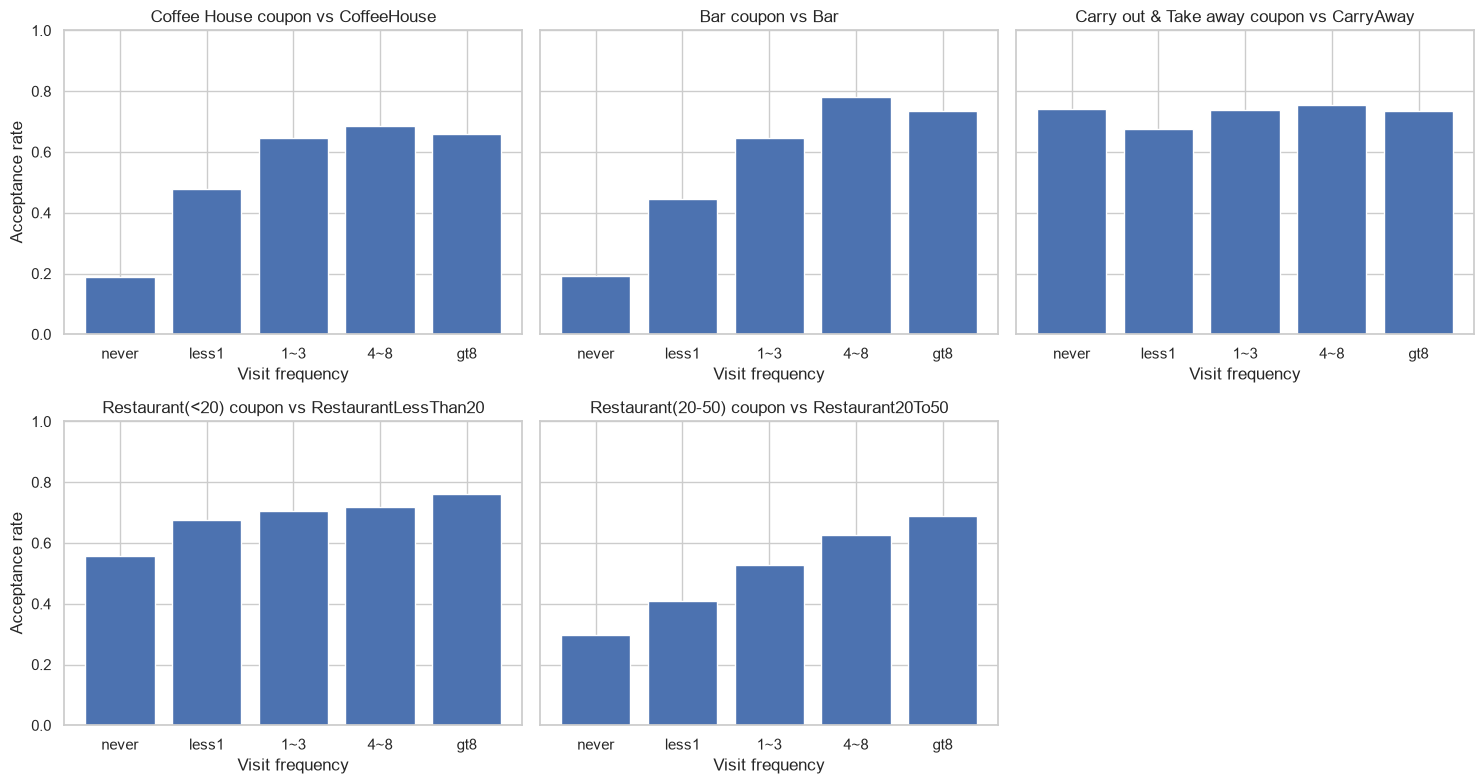

In [13]:
freq_order = ["never", "less1", "1~3", "4~8", "gt8"]
habit_map = {
    "Coffee House": "CoffeeHouse",
    "Bar": "Bar",
    "Carry out & Take away": "CarryAway",
    "Restaurant(<20)": "RestaurantLessThan20",
    "Restaurant(20-50)": "Restaurant20To50",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
axes = axes.ravel()

for ax, (coupon_name, habit_col) in zip(axes, habit_map.items()):
    subset = df[df["coupon"] == coupon_name]
    if subset.empty:
        ax.set_visible(False)
        continue
    rates = subset.groupby(habit_col)["Y"].mean()
    rates = rates.reindex([f for f in freq_order if f in rates.index])
    ax.bar(rates.index, rates.values, color="#4c72b0")
    ax.set_title(f"{coupon_name} coupon vs {habit_col}")
    ax.set_ylim(0, 1)
    ax.set_xlabel("Visit frequency")

for ax in axes[len(habit_map):]:
    ax.set_visible(False)

axes[0].set_ylabel("Acceptance rate")
axes[3].set_ylabel("Acceptance rate")
plt.tight_layout()
plt.show()

**Insight:** Acceptance rises with past visit frequency for coupons, from 20% for people who "never" go to 70% for people who go "gt8" times. The effect is strongest for **Bar coupon** and weakest for **Carry out & take away**.

**So what:** Past behaviour is a strong, actionable signal. Customers who already visit a type of place are the best audience for that coupon. This also explains why the habit columns should stay in the model.

### 3.7 Interactions: coupon type with passenger and time
Single-variable charts hide combinations. The heatmaps show the acceptance rate for each pair, which is where non-linear models can add value over logistic regression.

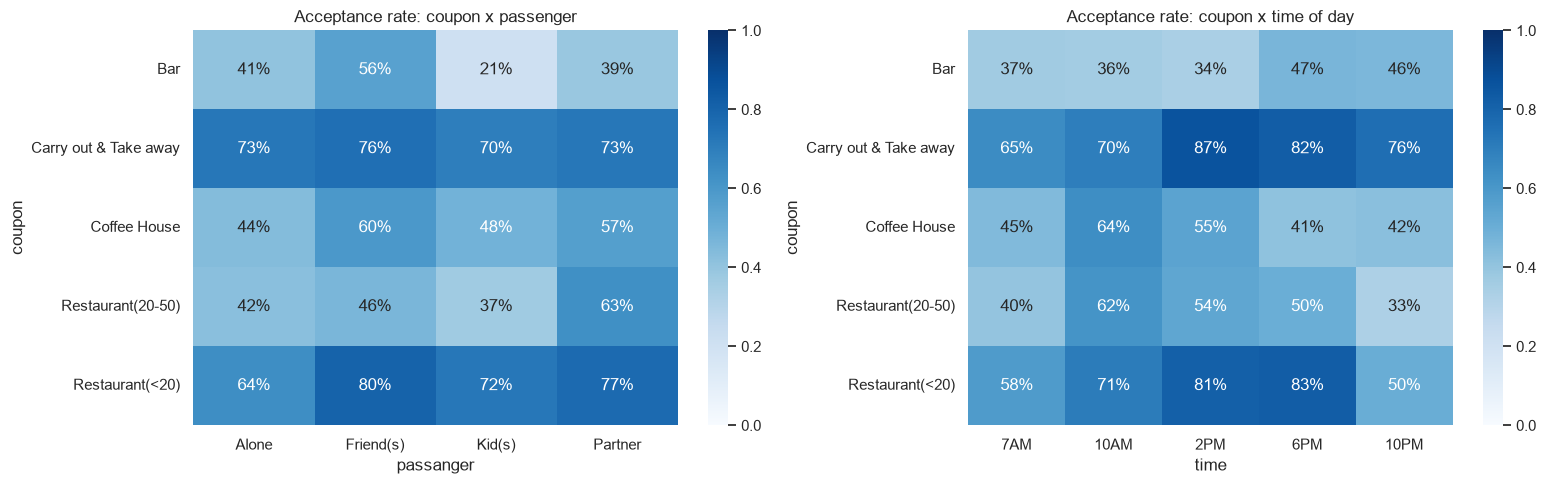

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

pivot_passenger = df.pivot_table(index="coupon", columns="passanger", values="Y", aggfunc="mean")
sns.heatmap(pivot_passenger, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Acceptance rate: coupon x passenger")

time_cols = [t for t in ["7AM", "10AM", "2PM", "6PM", "10PM"] if t in df["time"].unique()]
pivot_time = df.pivot_table(index="coupon", columns="time", values="Y", aggfunc="mean")[time_cols]
sns.heatmap(pivot_time, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Acceptance rate: coupon x time of day")

plt.tight_layout()
plt.show()

**Insight:** The best combination is **Carry out & Take away** coupons with **time of day** (87%), and the worst is **Bar** coupons with **Kids** (21%). For example, bar coupons are accepted 56% of the time when travelling with friends but only 21% with kids.

**So what:** The effect of one feature depends on another, so the relationship is **not purely additive**. This is the reason to try tree-based models (Random Forest, XGBoost) after the logistic regression baseline.

### EDA summary
1. **Coupon type** and **past visit habits** are the clearest drivers: take-away and low-cost restaurant coupons are accepted 64-80% of the time in every passenger group, while bar coupons range from 21% to 56%. People who never visit a coffee house or bar accept only about 19% of those coupons, versus about 65% for those who go 1 to 3 times a month.
2. **Context** (passenger, time of day, destination) changes acceptance by up to 35 points: bar coupons are accepted 56% of the time with friends but 21% with kids (35 points), $20-50 restaurant coupons 62% at 10AM but 33% at 10PM (29 points), and coffee house coupons 64% at 10AM but 41% at 6PM (23 points).
3. **Demographics** (age, gender, income) have a smaller effect
4. Several effects are **interactions**, so I expect tree-based models to beat the linear baseline.

## 4. Modelling approach
- **Encoding:** one-hot encoding for all categorical columns (`drop_first=True` to avoid duplicated information).
- **Split:** stratified 80/20 train/test, with a fixed random seed for reproducibility.
- **Models:** Logistic Regression as an interpretable baseline, then Random Forest and XGBoost to capture non-linear interactions.
- **Evaluation:** accuracy, precision, recall, F1 and ROC-AUC on the held-out test set, plus 5-fold cross-validated ROC-AUC on the training set to check stability.

In [15]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

X = pd.get_dummies(df.drop(columns=["Y"]), drop_first=True).astype(int)
# XGBoost does not allow these characters in column names
X.columns = X.columns.str.replace(r"[\[\]<>]", "", regex=True)
y = df["Y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Feature matrix:", X.shape)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Acceptance rate in train:", round(y_train.mean(), 3), "| in test:", round(y_test.mean(), 3))

Feature matrix: (12610, 91)
Train: (10088, 91) | Test: (2522, 91)
Acceptance rate in train: 0.568 | in test: 0.567


**Check:** one-hot encoding expanded the 24 original columns into 91 model features. The acceptance rate is almost identical in train (56.8%) and test (56.7%), which confirms the stratified split worked.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}
fitted = {}


def evaluate(name, model):
    """Fit a model, score it on the test set and cross-validate it on the training set."""
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")

    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "CV ROC-AUC (mean)": cv_auc.mean(),
        "CV ROC-AUC (std)": cv_auc.std(),
    }
    fitted[name] = model
    return pd.DataFrame(results).T.round(3)


evaluate("Logistic Regression", LogisticRegression(max_iter=2000))

,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC (mean),CV ROC-AUC (std)
Logistic Regression,0.678,0.702,0.751,0.726,0.723,0.738,0.017


**Baseline:** logistic regression reaches 67.8% accuracy and a ROC-AUC of 0.723. This is the number to beat. If the more complex models only improve slightly, the simpler and more explainable model would be the better business choice.

In [17]:
evaluate(
    "Random Forest",
    RandomForestClassifier(
        n_estimators=200,
        max_depth=14,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    ),
)

evaluate(
    "XGBoost",
    XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=5,
        eval_metric="logloss",
        random_state=42,
    ),
)

,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC (mean),CV ROC-AUC (std)
Logistic Regression,0.678,0.702,0.751,0.726,0.723,0.738,0.017
Random Forest,0.730,0.728,0.836,0.778,0.793,0.802,0.016
XGBoost,0.749,0.754,0.827,0.789,0.819,0.822,0.015


Random Forest is limited with `max_depth=14` and `min_samples_leaf=2` to reduce overfitting and keep the saved model small. XGBoost uses a moderate learning rate and depth for the same reason. This run may take one to three minutes because of the 5-fold cross-validation.

## 5. Model comparison

In [18]:
comparison = pd.DataFrame(results).T.sort_values("ROC-AUC", ascending=False).round(3)
best_name = comparison.index[0]
best_model = fitted[best_name]

print("Best model by ROC-AUC:", best_name)
comparison

Best model by ROC-AUC: XGBoost


,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC (mean),CV ROC-AUC (std)
XGBoost,0.749,0.754,0.827,0.789,0.819,0.822,0.015
Random Forest,0.730,0.728,0.836,0.778,0.793,0.802,0.016
Logistic Regression,0.678,0.702,0.751,0.726,0.723,0.738,0.017


**Result:** **XGBoost** performed best (ROC-AUC 0.819, F1 0.789, accuracy 74.9%). It improves on the logistic regression baseline by 0.096 ROC-AUC points.

**Stability:** the cross-validated ROC-AUC is 0.822 with a standard deviation of only 0.015, close to the test score (0.017), so the result is stable and not a lucky split. The gap between train-CV and test is small, which suggests no serious overfitting.

**Interpretation:** a ROC-AUC of 0.819 means the model ranks a randomly chosen accepted coupon above a randomly chosen rejected one 81.9% of the time. That is a strong result for survey data about stated intent.

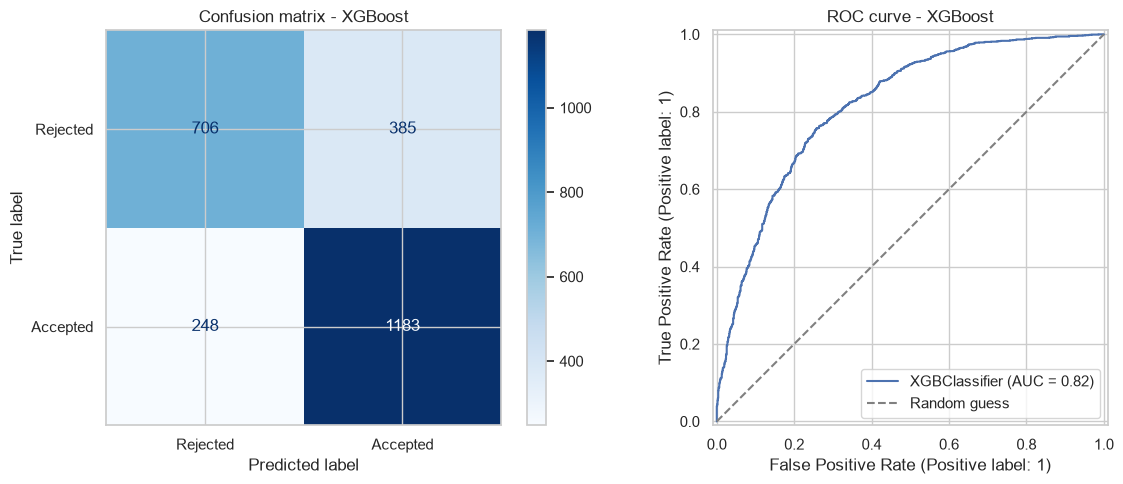

              precision    recall  f1-score   support

    Rejected       0.74      0.65      0.69      1091
    Accepted       0.75      0.83      0.79      1431

    accuracy                           0.75      2522
   macro avg       0.75      0.74      0.74      2522
weighted avg       0.75      0.75      0.75      2522



In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, display_labels=["Rejected", "Accepted"], cmap="Blues", ax=axes[0]
)
axes[0].set_title(f"Confusion matrix - {best_name}")

RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
axes[1].legend()
axes[1].set_title(f"ROC curve - {best_name}")

plt.tight_layout()
plt.show()

print(classification_report(y_test, best_model.predict(X_test), target_names=["Rejected", "Accepted"]))

**Insight:** The model correctly identifies 83% of accepted coupons and 74% of the coupons it predicts as "accepted" really are accepted. It makes 385 false positives and 248 false negatives.

**So what:** In marketing, a false positive costs the price of a wasted offer, while a false negative is a lost sale. Which error matters more depends on the cost of the coupon, which is why the threshold analysis in section 7 matters.

## 6. What drives acceptance? (explainability)
A model is only useful for a business if we can explain it. I use two views: built-in **feature importance** (how much the model relies on each feature) and **SHAP** (direction and size of each feature's effect).

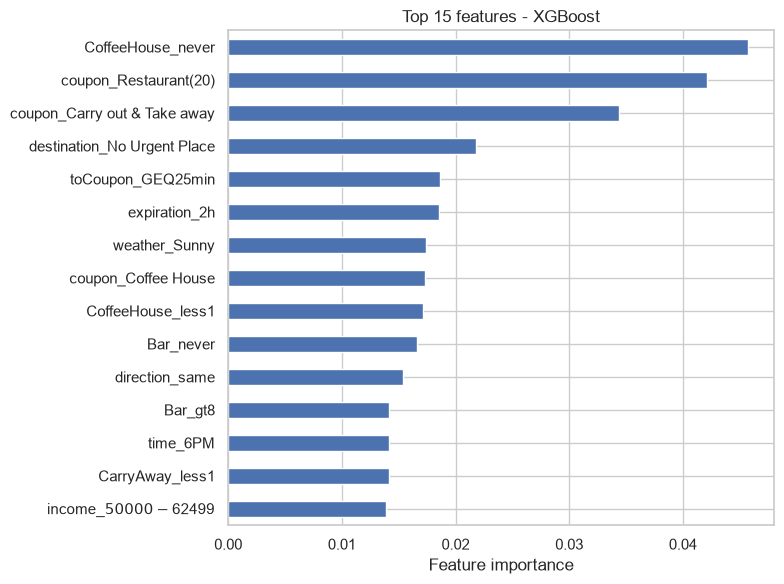

CoffeeHouse_never               0.0457
coupon_Restaurant(20)           0.0422
coupon_Carry out & Take away    0.0343
destination_No Urgent Place     0.0218
toCoupon_GEQ25min               0.0187
expiration_2h                   0.0185
weather_Sunny                   0.0174
coupon_Coffee House             0.0173
CoffeeHouse_less1               0.0171
Bar_never                       0.0166
direction_same                  0.0154
Bar_gt8                         0.0142
time_6PM                        0.0142
CarryAway_less1                 0.0141
income_$50000 - $62499          0.0139
dtype: float32

In [20]:
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=X_train.columns)
    label = "Feature importance"
else:
    importance = pd.Series(best_model.coef_[0], index=X_train.columns).abs()
    label = "Absolute coefficient"

top = importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
top[::-1].plot(kind="barh", color="#4c72b0")
plt.title(f"Top 15 features - {best_name}")
plt.xlabel(label)
plt.tight_layout()
plt.show()

top.round(4)

**Insight:** The top features are CoffeeHouse_never, coupon_Restaurant(20)  and coupon_Carry out & Take away. Together, the top 5 account for 52.9% of the total importance.

**Reading note:** because of one-hot encoding, a name like `coupon_Coffee House` means "the coupon is a Coffee House coupon". Several columns can come from the same original variable (for example, different `passanger` values).

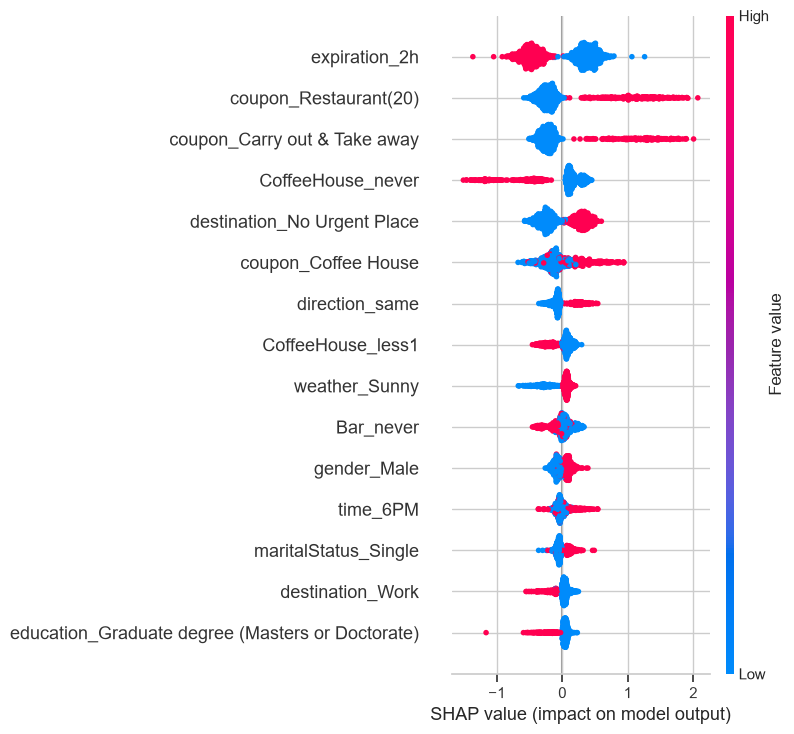

In [21]:
try:
    import shap

    sample = X_test.sample(min(1000, len(X_test)), random_state=42)
    shap_values = shap.TreeExplainer(best_model).shap_values(sample)

    if isinstance(shap_values, list):  # older shap with random forest
        shap_values = shap_values[1]
    elif getattr(shap_values, "ndim", 2) == 3:  # newer shap with random forest
        shap_values = shap_values[:, :, 1]

    shap.summary_plot(shap_values, sample, max_display=15)
except Exception as exc:
    print("SHAP plot skipped:", exc)

**How to read the SHAP plot:** each dot is one coupon decision. Dots to the **right** push the prediction towards "accepted", dots to the **left** towards "rejected". **Red** means a high feature value (for one-hot features, red means "yes, this category applies") and **blue** means low.

**Key drivers:**
1. coupon_Restaurant(20) pushes acceptance **up** when lasts upto 1 day and **down** when expires in 2 hour.
2. Travelling with friends pushes acceptance **up** .
3. Having never visited coffee houses pushes acceptance **down** when the coupon is for a coffee house.

These agree with / differ from the EDA findings in section 3 in the following way: ___.

## 7. Business view: choosing how many coupons to send
By default a model says "accepted" when the predicted probability is at least 0.5. A business can choose a different cut-off. A **higher** threshold sends fewer coupons but a larger share of them gets accepted (higher precision). A **lower** threshold reaches more acceptors but wastes more coupons (higher recall).

In [22]:
proba = best_model.predict_proba(X_test)[:, 1]

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred_t = (proba >= t).astype(int)
    rows.append(
        {
            "threshold": t,
            "coupons_sent": int(pred_t.sum()),
            "precision": precision_score(y_test, pred_t),
            "recall": recall_score(y_test, pred_t),
            "f1": f1_score(y_test, pred_t),
        }
    )

threshold_table = pd.DataFrame(rows).round(3)
threshold_table

,threshold,coupons_sent,precision,recall,f1
0,0.3,1972,0.686,0.945,0.795
1,0.4,1759,0.722,0.887,0.796
2,0.5,1568,0.754,0.827,0.789
3,0.6,1315,0.798,0.734,0.765
4,0.7,1011,0.837,0.591,0.693
5,0.8,674,0.864,0.407,0.553


**Insight:** At a threshold of 0.5 the model sends 1,568 coupons and 75.4% of them are accepted. At 0.7 it sends only 1,011 coupons, but 83.7% are accepted. Compared with sending a coupon to everyone (about 57% acceptance), targeting with the model lifts the acceptance rate by 18.4 percentage points.

**So what:** If a coupon is cheap, use a lower threshold to reach more people. If each coupon is expensive, use a higher threshold. The best cut-off should be chosen from the real cost of a coupon and the profit from an accepted one.

## 8. Save results
Saving the comparison table and the best model so the results can be reused without re-training.

In [23]:
from pathlib import Path
import joblib

Path("models").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

comparison.to_csv("outputs/model_comparison.csv")
threshold_table.to_csv("outputs/threshold_analysis.csv", index=False)
joblib.dump({"model": best_model, "columns": list(X.columns)}, "models/best_model.pkl", compress=3)

print("Saved: outputs/model_comparison.csv, outputs/threshold_analysis.csv, models/best_model.pkl")

Saved: outputs/model_comparison.csv, outputs/threshold_analysis.csv, models/best_model.pkl


In [24]:
# Model result
base = comparison.loc["Logistic Regression", "ROC-AUC"]
best = comparison.loc[best_name, "ROC-AUC"]
print("Best model:", best_name)
print("ROC-AUC:", best, "| F1:", comparison.loc[best_name, "F1"])
print("Baseline ROC-AUC:", base, "| improvement (points):", round((best - base) * 100, 1))

# Best and worst coupon x context combinations (groups with at least 150 rows)
rows = []
for ctx in ["passanger", "time", "destination", "weather"]:
    g = df.groupby(["coupon", ctx])["Y"].agg(["mean", "count"]).reset_index()
    g.columns = ["coupon", "context_value", "acceptance", "n"]
    g.insert(1, "context", ctx)
    rows.append(g)
combos = pd.concat(rows)
combos = combos[combos["n"] >= 150].copy()
combos["acceptance"] = (combos["acceptance"] * 100).round(1)
print("\nHIGHEST acceptance combinations")
print(combos.sort_values("acceptance", ascending=False).head(5).to_string(index=False))
print("\nLOWEST acceptance combinations")
print(combos.sort_values("acceptance").head(5).to_string(index=False))

# Habit effect by coupon type
for coupon_name, habit_col in habit_map.items():
    t = df[df["coupon"] == coupon_name].groupby(habit_col)["Y"].agg(["mean", "count"])
    t["mean"] = (t["mean"] * 100).round(1)
    print(f"\n{coupon_name} vs {habit_col}")
    print(t.reindex([f for f in freq_order if f in t.index]))

# Expiry effect
exp = df.groupby("expiration")["Y"].agg(["mean", "count"])
exp["mean"] = (exp["mean"] * 100).round(1)
print("\nExpiry")
print(exp)

Best model: XGBoost
ROC-AUC: 0.819 | F1: 0.789
Baseline ROC-AUC: 0.723 | improvement (points): 9.6

HIGHEST acceptance combinations
               coupon   context context_value  acceptance   n
Carry out & Take away      time           2PM        86.7 218
      Restaurant(<20)      time           6PM        82.8 748
Carry out & Take away      time           6PM        82.4 433
      Restaurant(<20)      time           2PM        81.5 696
      Restaurant(<20) passanger     Friend(s)        80.1 826

LOWEST acceptance combinations
           coupon   context context_value  acceptance   n
              Bar passanger        Kid(s)        21.1 204
Restaurant(20-50)   weather         Snowy        30.5 177
              Bar   weather         Snowy        31.9 238
Restaurant(20-50)      time          10PM        32.9 380
              Bar      time          10AM        36.1 443

Coffee House vs CoffeeHouse
             mean  count
CoffeeHouse             
never        18.9    927
less1       

## 9. Conclusion and recommendations

**Result:** **XGBoost** predicts coupon acceptance with a ROC-AUC of **0.819** and an F1 of **0.789**, improving on the baseline by **9.6** points.

### Recommendations
1. **Target by coupon and context:** prioritise **take-away and low-cost restaurant (under $20)** coupons in situations such as **mealtime hours (take-away at 2PM, low-cost restaurants at 6PM)**, where acceptance reaches **87% and 83%**.
2. **Target by habit:** send coffee house, bar and expensive-restaurant coupons mainly to people who already visit that kind of place at least **1** time a month (acceptance **about 65% for coffee houses and bars**, versus **about 19%** for people who never go).
3. **Reduce waste:** avoid sending **bar** coupons when **travelling with kids** (acceptance only **21%**), and avoid **$20-50 restaurant** coupons in **snowy weather** (acceptance only **31%**).
4. **Offer design:** use a **1-day** expiry window, which performs **12.8** points better (62.4% vs 49.6% for 2-hour coupons).
5. **Use probabilities, not just yes/no:** rank coupons per driver by predicted probability and send only those above a threshold set from the real cost of a coupon.

### Limitations
- The data comes from a **survey of hypothetical scenarios**, so stated intent may differ from real behaviour.
- There is no user history over time, no real location and no actual purchase data.
- Performance is bounded by what drivers state in a survey (a ROC-AUC of 0.819 suggests there is inherent randomness in the answers).
- Categories such as "Kid(s)" are small, so conclusions about them are less reliable.

### Next steps
- Tune hyperparameters with a cross-validated search and test calibrated probabilities.
- Compare with other models such as LightGBM or CatBoost, which handle categorical data natively.
- Choose the final threshold from a cost and profit model.
- Validate on real campaign data (A/B test) before relying on the model in production.
- Wrap the model in a small Streamlit app so a user can pick a driving situation and see the predicted acceptance probability.